# A minimal differentiable canopy model in JAX

This notebook runs `canopy_jax.py`, a small CLM5-style canopy model (Farquhar photosynthesis, Medlyn stomatal conductance, leaf energy balance, 10-layer canopy), then uses **gradients** to recover two parameters, `Vcmax25` and Medlyn `g1`, from synthetic flux observations.

Sections:
1. Forward run over 5 synthetic days
2. Check that autodiff gradients match finite differences
3. Gradient-based calibration
4. Vectorizing over many sites with `vmap`

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import jax, jax.numpy as jnp
import optax
from canopy_jax import Params, Forcing, run, canopy, make_forcing, esat, TFRZ

print("JAX", jax.__version__, "| devices:", jax.devices())
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

JAX 0.12.0.1 | devices: [CpuDevice(id=0)]


## 1. Forward run

In [2]:
hours, forcing = make_forcing(n_days=5, seed=0)
truth = Params(vcmax25=60.0, g1=4.0)

t0 = time.time(); out = run(forcing, truth); jax.block_until_ready(out)
print(f"first call (compile + run): {time.time()-t0:.2f} s")
t0 = time.time(); out = run(forcing, truth); jax.block_until_ready(out)
print(f"second call (compiled):     {(time.time()-t0)*1000:.1f} ms for {hours.size} half-hours x 10 layers")
print("max |energy-balance residual| over all leaves:", float(out['max_energy_resid'].max()), "W m-2")

first call (compile + run): 3.12 s
second call (compiled):     22.2 ms for 240 half-hours x 10 layers
max |energy-balance residual| over all leaves: 2.58551513532268e-12 W m-2


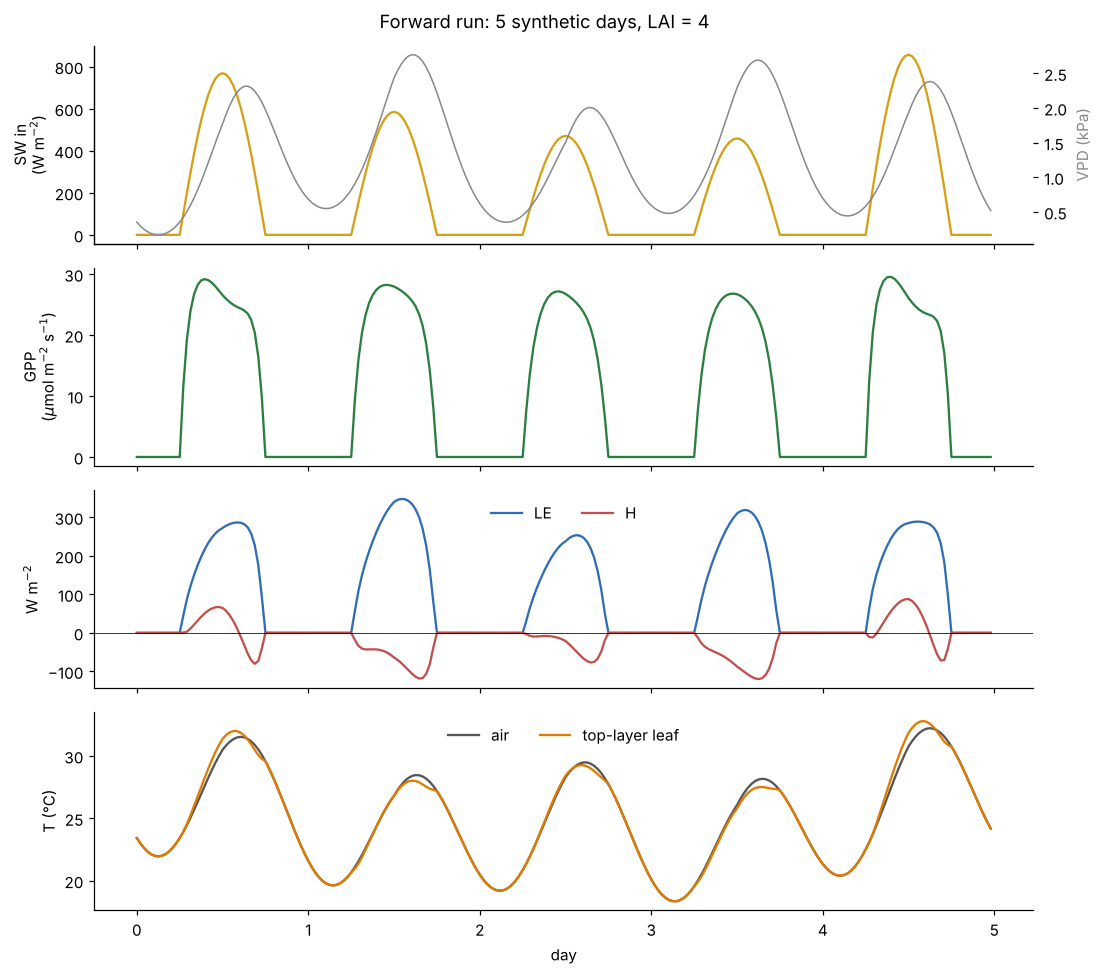

In [3]:
vpd = (np.asarray(esat(forcing.tair)) - np.asarray(forcing.ea)) / 1000
d = hours / 24
fig, ax = plt.subplots(4, 1, figsize=(10, 9), sharex=True)
ax[0].plot(d, forcing.sw, c="#d4a017"); ax[0].set_ylabel("SW in\n(W m$^{-2}$)")
a2 = ax[0].twinx(); a2.plot(d, vpd, c="#888", lw=1); a2.set_ylabel("VPD (kPa)", color="#888")
ax[1].plot(d, out["gpp"], c="#2a7f3f"); ax[1].set_ylabel("GPP\n($\\mu$mol m$^{-2}$ s$^{-1}$)")
ax[2].plot(d, out["le"], c="#2f6db5", label="LE"); ax[2].plot(d, out["h"], c="#c0504d", label="H")
ax[2].axhline(0, c="k", lw=0.5); ax[2].legend(frameon=False, ncol=2); ax[2].set_ylabel("W m$^{-2}$")
ax[3].plot(d, np.asarray(forcing.tair) - TFRZ, c="#555", label="air")
ax[3].plot(d, np.asarray(out["tleaf_top"]) - TFRZ, c="#e07b00", label="top-layer leaf")
ax[3].legend(frameon=False, ncol=2); ax[3].set_ylabel("T (°C)"); ax[3].set_xlabel("day")
fig.suptitle("Forward run: 5 synthetic days, LAI = 4"); fig.tight_layout()
fig.savefig("fig1_forward_run.png", dpi=150); plt.show()

Things to notice: GPP tracks light but is suppressed on hot, dry afternoons (high VPD closes stomata in the Medlyn model). Top-of-canopy leaves run a few degrees warmer than air at midday. Latent heat dominates, and sensible heat can go negative when air is very dry because the model has no soil-moisture stress (see limitations).

## 2. Gradient check

The two nested solvers (intercellular CO₂ and leaf temperature) find their roots *without* tracking gradients, then take one differentiable Newton step. By the implicit function theorem that gives exact gradients. Here we confirm against central finite differences.

In [4]:
obs_sd = {"gpp": 1.5, "le": 20.0}

def make_loss(obs):
    def loss(log_theta):
        v, g1 = jnp.exp(log_theta)
        o = run(forcing, truth._replace(vcmax25=v, g1=g1))
        return (jnp.mean(((o["gpp"] - obs["gpp"]) / obs_sd["gpp"])**2)
                + jnp.mean(((o["le"] - obs["le"]) / obs_sd["le"])**2))
    return jax.jit(loss)

# synthetic observations = truth + noise
rng = np.random.default_rng(1)
obs = {k: out[k] + rng.normal(0, obs_sd[k], hours.size) * (np.asarray(forcing.sw) > 0) for k in obs_sd}
loss = make_loss(obs)

theta = jnp.log(jnp.array([35.0, 7.0]))
ad = jax.grad(loss)(theta)
eps = 1e-5
fd = jnp.array([(loss(theta + eps*e) - loss(theta - eps*e)) / (2*eps) for e in jnp.eye(2)])
for name, a, f in zip(["d/dlog Vcmax25", "d/dlog g1"], ad, fd):
    print(f"{name:15s} autodiff = {float(a): .8e}   finite diff = {float(f): .8e}   rel err = {abs(float(a-f)/float(f)):.1e}")

d/dlog Vcmax25  autodiff = -2.94197836e+01   finite diff = -2.94197836e+01   rel err = 1.3e-10
d/dlog g1       autodiff =  9.17817941e+00   finite diff =  9.17817941e+00   rel err = 4.6e-10


## 3. Calibration: recover Vcmax25 and g1 from noisy GPP + LE

In [5]:
opt = optax.adam(0.05)
theta = jnp.log(jnp.array([35.0, 7.0]))     # deliberately wrong start (truth: 60, 4)
state = opt.init(theta)

@jax.jit
def step(theta, state):
    l, g = jax.value_and_grad(loss)(theta)
    upd, state = opt.update(g, state)
    return optax.apply_updates(theta, upd), state, l

hist = []
t0 = time.time()
for i in range(250):
    theta, state, l = step(theta, state)
    hist.append((float(l), *np.exp(np.asarray(theta))))
hist = np.array(hist)
print(f"250 Adam steps in {time.time()-t0:.1f} s")
print(f"recovered Vcmax25 = {hist[-1,1]:.2f} (truth 60),  g1 = {hist[-1,2]:.3f} (truth 4)")

250 Adam steps in 13.3 s
recovered Vcmax25 = 59.46 (truth 60),  g1 = 4.031 (truth 4)


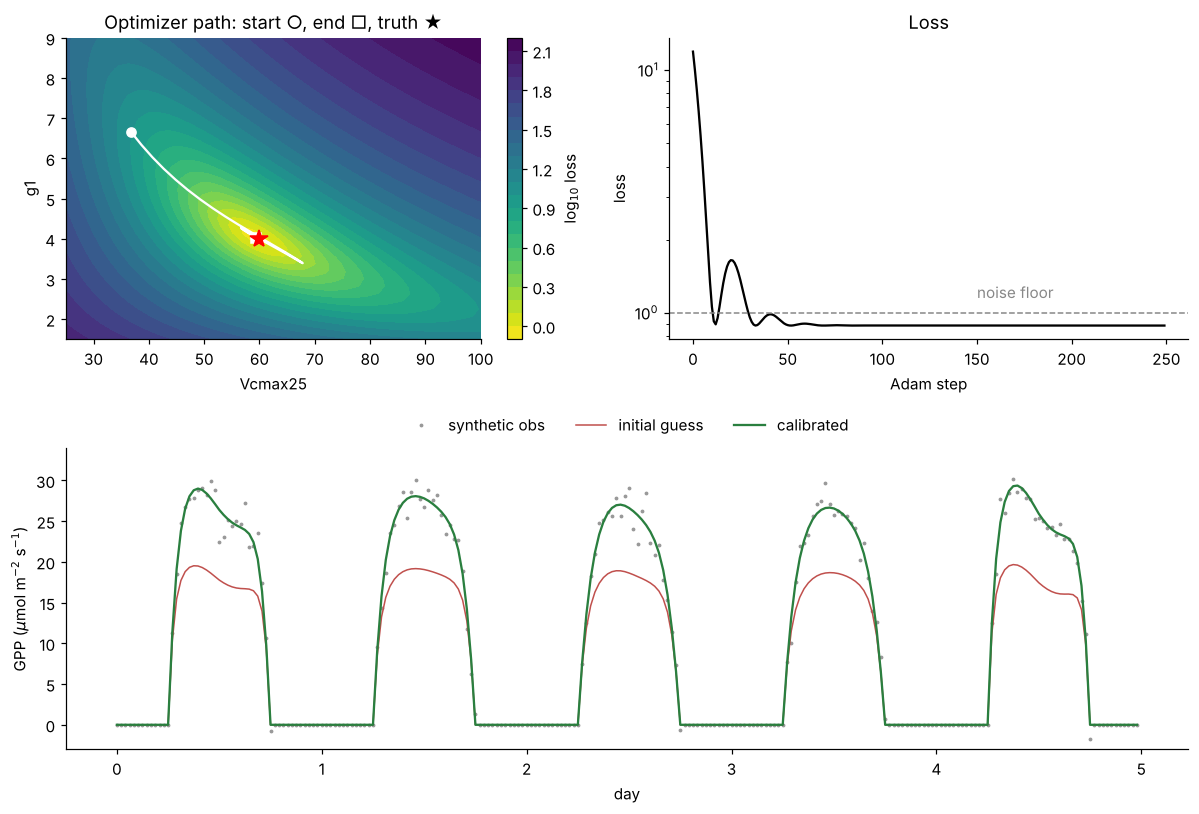

In [6]:
# loss landscape for context
vs = np.linspace(25, 100, 41); gs = np.linspace(1.5, 9, 41)
Z = np.array([[float(loss(jnp.log(jnp.array([v, g])))) for v in vs] for g in gs])

fit = run(forcing, truth._replace(vcmax25=hist[-1,1], g1=hist[-1,2]))
start = run(forcing, truth._replace(vcmax25=35.0, g1=7.0))

fig = plt.figure(figsize=(11, 7.5))
gsp = fig.add_gridspec(2, 2)
a = fig.add_subplot(gsp[0, 0])
cs = a.contourf(vs, gs, np.log10(Z), levels=25, cmap="viridis_r"); fig.colorbar(cs, ax=a, label="log$_{10}$ loss")
a.plot(hist[:,1], hist[:,2], c="w", lw=1.5); a.plot(hist[0,1], hist[0,2], "wo"); a.plot(hist[-1,1], hist[-1,2], "ws", ms=6); a.plot(60, 4, "r*", ms=12)
a.set_xlabel("Vcmax25"); a.set_ylabel("g1"); a.set_title("Optimizer path: start ○, end □, truth ★")
b = fig.add_subplot(gsp[0, 1])
b.semilogy(hist[:,0], c="k"); b.set_xlabel("Adam step"); b.set_ylabel("loss"); b.set_title("Loss")
b.axhline(2.0 * (np.asarray(forcing.sw) > 0).mean(), ls="--", c="#888", lw=1); b.text(150, 2.0*(np.asarray(forcing.sw) > 0).mean()*1.15, "noise floor", color="#888")
c = fig.add_subplot(gsp[1, :])
dd = hours / 24
c.plot(dd, obs["gpp"], ".", c="#999", ms=3, label="synthetic obs")
c.plot(dd, start["gpp"], c="#c0504d", lw=1, label="initial guess")
c.plot(dd, fit["gpp"], c="#2a7f3f", lw=1.5, label="calibrated")
c.set_xlabel("day"); c.set_ylabel("GPP ($\\mu$mol m$^{-2}$ s$^{-1}$)"); c.legend(frameon=False, ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0)); c.set_ylim(-3, 34)
fig.tight_layout(); fig.savefig("fig2_calibration.png", dpi=150); plt.show()

## 4. Many sites at once with `vmap`

In [7]:
n_sites = 500
rng = np.random.default_rng(2)
lai = jnp.asarray(rng.uniform(1, 6, n_sites))
# same weather everywhere, different LAI per site: shape (sites, time)
f_sites = jax.tree.map(lambda x: jnp.broadcast_to(x, (n_sites, hours.size)), forcing)._replace(
    lai=jnp.broadcast_to(lai[:, None], (n_sites, hours.size)))
run_sites = jax.jit(jax.vmap(jax.vmap(canopy, in_axes=(0, None)), in_axes=(0, None)))

jax.block_until_ready(run_sites(f_sites, truth))
t0 = time.time(); o = run_sites(f_sites, truth); jax.block_until_ready(o)
n_leaf = n_sites * hours.size * 10
print(f"{n_sites} sites x {hours.size} steps x 10 layers = {n_leaf:,} leaf solves in {time.time()-t0:.2f} s on {jax.devices()[0].platform.upper()}")
print("Same code runs on a GPU unchanged: install jax[cuda12] and JAX will use it automatically.")

500 sites x 240 steps x 10 layers = 1,200,000 leaf solves in 18.59 s on CPU
Same code runs on a GPU unchanged: install jax[cuda12] and JAX will use it automatically.


## Limitations and next steps

**Simplified relative to CLM5:** no sunlit/shaded leaf split or diffuse/direct radiation (CLM uses two-stream radiation); no within-canopy air temperature/humidity or aerodynamic resistance; no soil-moisture stress (`btran = 1`); no TPU limitation; cs = ca; constant latent heat. The model also isn't validated against CLM output.

**Natural next steps:**
1. Add soil-moisture stress and sunlit/shaded leaves, then compare against CLM single-point (PTCLM) output for one site.
2. Calibrate against real eddy-covariance data (e.g. an AmeriFlux or FLUXNET site) instead of synthetic observations.
3. Replace a parameter with a small neural network (e.g. g1 as a function of soil moisture) and train it end-to-end, since the whole model is differentiable.
4. Benchmark on a GPU against a NumPy version of the same physics.